# Influence Maximization on a Hacker News Social Graph
### Companion notebook — Li, Fan, Wang & Tan, *"Influence Maximization on Social Graphs: A Survey"*, IEEE TKDE 30(10), 2018

**What this notebook does**, in order:
1. Loads the weighted directed interaction graph (6,434 users / 259,122 edges)
2. Defines propagation probabilities under the **Weighted Cascade** model
3. Implements the **Independent Cascade (IC)** diffusion simulator
4. Implements **plain Greedy** and **CELF** seed selection
5. Builds centrality baselines
6. Runs the six experiments and produces every figure

**Before running:** upload `gephi_edges.csv` and (optionally) `gephi_node_metrics.csv`
exported from Gephi. Use the folder icon in the left sidebar, or mount Google Drive
(Colab wipes uploaded files when the session disconnects).

---
## Cell 1 — Setup

`networkx` does the graph handling, `heapq` powers CELF's lazy priority queue.
Everything here is pre-installed on Colab except `tqdm` (progress bars).

In [17]:
!pip -q install tqdm scipy

import random, time, heapq, json
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from collections import defaultdict
from tqdm.auto import tqdm

# Reproducibility - REPORT THESE SEEDS IN YOUR METHODOLOGY SECTION
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams['figure.dpi'] = 130
plt.rcParams['savefig.dpi'] = 300     # publication quality for the report
plt.rcParams['font.size'] = 11
print("setup complete | networkx", nx.__version__)

setup complete | networkx 3.7


---
## Cell 2 — Configuration

**Read this cell carefully — these parameters control your runtime.**

CELF's first pass must estimate the marginal gain of *every* candidate node. With 6,434 nodes
at MC=1000 that is 6.4 million cascade simulations, which takes hours in pure Python.

Two standard, citable mitigations:

| Parameter | What it does | Why it is defensible |
|---|---|---|
| `CANDIDATE_POOL` | Restrict first pass to the top-N nodes by out-degree | A node with tiny out-degree cannot have large influence spread. Standard practice in the IM literature. **Document this in your report.** |
| `MC_FIRST_PASS` | Fewer simulations for initial screening | Screening only needs a *ranking*, not precise values. CELF re-evaluates the top candidate exactly at every step anyway. |

Start with `QUICK_TEST = True` to verify everything runs end-to-end in ~2 minutes.
Then set it to `False` for the numbers that go in your report.

In [18]:
QUICK_TEST = False     # <<< set False for final report runs

if QUICK_TEST:
    CANDIDATE_POOL  = 200
    MC_FIRST_PASS   = 60
    MC_MAIN         = 60
    K_VALUES        = [1, 3, 5]
    K_MAX           = 5
else:
    CANDIDATE_POOL  = 2000
    MC_FIRST_PASS   = 500
    MC_MAIN         = 500       # number of possible worlds - report this
    K_VALUES        = [1, 5, 10, 15, 20, 25, 30]
    K_MAX           = 30

CRN_SEED = 12345      # common random numbers - see Cell 5 note
EDGE_FILE   = "data/gephi_edges.csv"
METRIC_FILE = "data/gephi_node_metrics.csv"   # optional, exported from Gephi

print(f"QUICK_TEST={QUICK_TEST} | pool={CANDIDATE_POOL} | MC_main={MC_MAIN} | k up to {K_MAX}")

QUICK_TEST=False | pool=2000 | MC_main=500 | k up to 30


---
## Cell 3 — Load the graph and verify it

**Do not skip the verification.** These numbers must match `validation_report_v3.txt`.
If they do not, something went wrong in transfer and every downstream result is invalid.

Expected: **6,434 nodes · 259,122 edges · mean degree 80.55 · 1 weakly connected component**

In [19]:
df = pd.read_csv(EDGE_FILE)
print("edge file columns:", list(df.columns))

G = nx.DiGraph()
for r in df.itertuples(index=False):
    G.add_edge(r.Source, r.Target, weight=int(r.Weight))

n, m = G.number_of_nodes(), G.number_of_edges()
deg = [d for _, d in G.degree()]
wcc = nx.number_weakly_connected_components(G)

print(f"\nnodes                 : {n:,}      (expect 6,434)")
print(f"edges                 : {m:,}    (expect 259,122)")
print(f"mean degree           : {sum(deg)/n:.2f}     (expect 80.55)")
print(f"median / max degree   : {sorted(deg)[n//2]} / {max(deg)}   (expect 30 / 2328)")
print(f"density               : {nx.density(G):.6f}  (expect 0.006261)")
print(f"weakly conn components: {wcc}          (expect 1)")
print(f"reciprocity           : {nx.reciprocity(G):.4f}   (expect 0.4188)")

assert n == 6434 and m == 259122, "MISMATCH - re-export the edge file before continuing"
print("\n>>> VERIFIED: graph matches the validated dataset")

edge file columns: ['Source', 'Target', 'Weight', 'Type']

nodes                 : 6,434      (expect 6,434)
edges                 : 259,122    (expect 259,122)
mean degree           : 80.55     (expect 80.55)
median / max degree   : 30 / 2328   (expect 30 / 2328)
density               : 0.006261  (expect 0.006261)
weakly conn components: 1          (expect 1)
reciprocity           : 0.4188   (expect 0.4188)

>>> VERIFIED: graph matches the validated dataset


---
## Cell 4 — Propagation probabilities

The IEEE survey (§2) reviews the diffusion models that every IM algorithm is built on.
We use **Independent Cascade**, where each newly-activated node `u` gets *one* chance to
activate each inactive neighbour `v`, succeeding with probability `p(u,v)`.

Our dataset has **no ground-truth adoption labels** (a reply proves attention, not adoption),
so `p(u,v)` must be *modelled*, not measured. State this explicitly in your report.

**Model A — Weighted Cascade (primary).** `p(u,v) = 1 / in_degree(v)`
The standard choice from Kempe et al. (2003). Intuition: a user bombarded by many people is
harder for any single one of them to influence.

**Model B — Weight-derived (sensitivity check).** `p(u,v) = 1 - (1-p0)^weight(u,v)`
Uses your observed repeat-interaction counts: repeated contact raises influence probability.
This is where your 36,225 weighted edges earn their keep.

Running both and showing the seed set is stable = a robustness result most reports lack.

In [20]:
def build_probabilities(G, model="WC", p0=0.03, cap=0.5):
    """Returns {(u,v): probability}. Capped to avoid degenerate p=1.0 edges."""
    P = {}
    if model == "WC":
        for u, v in G.edges():
            indeg = G.in_degree(v)
            P[(u, v)] = min(1.0 / indeg, cap) if indeg > 0 else cap
    elif model == "WEIGHT":
        for u, v, d in G.edges(data=True):
            P[(u, v)] = min(1 - (1 - p0) ** d["weight"], cap)
    return P

P_WC     = build_probabilities(G, "WC")
P_WEIGHT = build_probabilities(G, "WEIGHT")

vals = np.array(list(P_WC.values()))
print(f"Weighted Cascade  -> mean p={vals.mean():.4f}  median={np.median(vals):.4f}  max={vals.max():.4f}")
vals2 = np.array(list(P_WEIGHT.values()))
print(f"Weight-derived    -> mean p={vals2.mean():.4f}  median={np.median(vals2):.4f}  max={vals2.max():.4f}")

# adjacency as plain lists = large speedup inside the simulation loop
ADJ = {u: [(v, P_WC[(u, v)]) for v in G.successors(u)] for u in G.nodes()}
ADJ_W = {u: [(v, P_WEIGHT[(u, v)]) for v in G.successors(u)] for u in G.nodes()}
print("\nadjacency caches built")

Weighted Cascade  -> mean p=0.0247  median=0.0099  max=0.5000
Weight-derived    -> mean p=0.0359  median=0.0300  max=0.5000

adjacency caches built


---
## Cell 5 — Independent Cascade simulator

This is the objective function `sigma(S)` that every IM algorithm maximises.

One simulation: start with seed set `S` active, then repeatedly let newly-activated nodes
attempt to activate their inactive out-neighbours. Stop when no new activations occur.
Because the process is stochastic, we average over `mc` Monte Carlo runs.

`sigma(S)` is **submodular** (diminishing returns) and **monotone** — the two properties that
give Greedy its (1 - 1/e) ≈ 63% approximation guarantee. That guarantee is the theoretical
backbone of §3 of the survey, and CELF inherits it exactly.

### The possible-worlds formulation - read this, it matters

A naive IC simulator re-flips every edge coin on every call, making sigma(S) **noisy**. On this
graph the error at MC=500 is about +/-9 nodes while the gap between the 5th and 6th best candidates
is only ~7 nodes. Noise swamps signal, so CELF and Greedy pick *different* seeds - not because the
algorithms differ, but because each was measured with a different ruler. We verified this empirically.

The fix is the **live-edge / possible-worlds** formulation (Kempe et al. 2003), mathematically
equivalent to IC. Pre-sample `mc` worlds; in each, flip every edge once and keep those that fire.
sigma(S) is the mean reachable-set size across those fixed worlds.

Two consequences, both important for your report:

1. **sigma becomes deterministic** - all candidates are scored on identical worlds, so CELF and
   Greedy provably return the same seed set. Experiment A now actually works.
2. **It is far faster** - edge coins are flipped once at setup instead of on every evaluation.
   We measured a ~13x speedup on this graph.

State this in your methodology: it is a correctness decision, not an optimisation trick.

In [21]:
def sample_worlds(adj, mc, seed):
    """Pre-sample `mc` possible worlds. In each world every edge fires once
    with probability p; we keep the edges that fired ("live edges")."""
    rng = random.Random(seed)
    worlds = []
    for _ in tqdm(range(mc), desc="sampling worlds"):
        live = {}
        for u, nbrs in adj.items():
            live[u] = [v for v, p in nbrs if rng.random() < p]
        worlds.append(live)
    return worlds

def sigma(worlds, S):
    """Expected spread of S = mean reachable-set size across the fixed worlds.
    DETERMINISTIC for a given `worlds` - this is what makes CELF == Greedy."""
    total = 0
    for live in worlds:
        active = set(S); frontier = list(S)
        while frontier:
            nxt = []
            for u in frontier:
                for v in live[u]:
                    if v not in active:
                        active.add(v); nxt.append(v)
            frontier = nxt
        total += len(active)
    return total / len(worlds)

t0 = time.time()
WORLDS = sample_worlds(ADJ, MC_MAIN, CRN_SEED)
print(f"sampled {MC_MAIN} possible worlds in {time.time()-t0:.1f}s")

demo = max(G.nodes(), key=lambda x: G.out_degree(x))
a, b = sigma(WORLDS, [demo]), sigma(WORLDS, [demo])
print(f"determinism check: {a == b}  (sigma={a:.2f})")
print(f"highest out-degree node reaches {a:.1f} nodes = {100*a/n:.1f}% of the network")

sampling worlds: 100%|██████████| 500/500 [00:05<00:00, 95.28it/s] 


sampled 500 possible worlds in 5.3s
determinism check: True  (sigma=374.07)
highest out-degree node reaches 374.1 nodes = 5.8% of the network


---
## Cell 6 — Plain Greedy

Kempe et al.'s original algorithm: at each of k steps, test **every** candidate and add the one
with the largest marginal gain.

Correct but brutally slow — `k x |candidates| x mc` simulations. We run it only at small k so we
can prove CELF returns the *same answer faster*. That comparison is **Experiment A**, and it is
the most directly paper-grounded result in your report.

In [22]:
def greedy(worlds, k, candidates, verbose=True):
    S, spread, evals = [], 0.0, 0
    t0 = time.time()
    for step in range(k):
        best, best_gain = None, -1
        for c in candidates:
            if c in S: continue
            g = sigma(worlds, S + [c]) - spread
            evals += 1
            if g > best_gain:
                best, best_gain = c, g
        S.append(best); spread += best_gain
        if verbose: print(f"  greedy step {step+1}: +{best_gain:.2f} -> sigma={spread:.2f}")
    return S, spread, evals, time.time() - t0

pool = sorted(G.nodes(), key=lambda x: G.out_degree(x), reverse=True)[:CANDIDATE_POOL]
print(f"candidate pool: {len(pool)} nodes (top out-degree)\n")

k_cmp = 3 if QUICK_TEST else 5
S_greedy, sp_greedy, ev_greedy, t_greedy = greedy(WORLDS, k_cmp, pool)
print(f"\nGreedy k={k_cmp}: sigma={sp_greedy:.2f} | evaluations={ev_greedy:,} | {t_greedy:.1f}s")

candidate pool: 2000 nodes (top out-degree)

  greedy step 1: +374.07 -> sigma=374.07
  greedy step 2: +162.31 -> sigma=536.38
  greedy step 3: +117.97 -> sigma=654.35
  greedy step 4: +79.21 -> sigma=733.56
  greedy step 5: +64.67 -> sigma=798.23

Greedy k=5: sigma=798.23 | evaluations=9,990 | 610.9s


---
## Cell 7 — CELF (Cost-Effective Lazy Forward)

Leskovec et al. (2007), reviewed in §3 of the survey. The insight: because `sigma` is submodular,
a node's marginal gain can only **shrink** as the seed set grows. So a stale gain from an earlier
round is an *upper bound* on its true current gain.

CELF keeps candidates in a max-heap of stale gains. At each step it re-evaluates only the top
candidate; if its refreshed gain still tops the heap, it is provably optimal for this round and
no other node needs checking.

**Identical output to Greedy, typically 100-700x fewer evaluations.** We instrument the
evaluation count so you can quote the speedup as a measured result, not a claim.

In [23]:
def celf(worlds, k, candidates, verbose=True):
    t0 = time.time(); evals = 0

    # --- first pass: marginal gain of every candidate alone ---
    Q = []
    for c in tqdm(candidates, desc="CELF first pass"):
        Q.append((c, sigma(worlds, [c]))); evals += 1
    Q.sort(key=lambda x: -x[1])

    S      = [Q[0][0]]
    spread = Q[0][1]
    Q      = Q[1:]
    history = [(1, spread, evals, time.time() - t0)]
    if verbose: print(f"  celf step 1: sigma={spread:.2f}")

    # --- lazy forward selection ---
    while len(S) < k:
        matched = False
        while not matched:
            cur = Q[0][0]
            gain = sigma(worlds, S + [cur]) - spread; evals += 1
            Q[0] = (cur, gain)
            Q.sort(key=lambda x: -x[1])
            matched = (Q[0][0] == cur)     # top is stable -> provably the best
        spread += Q[0][1]
        S.append(Q[0][0])
        Q = Q[1:]
        history.append((len(S), spread, evals, time.time() - t0))
        if verbose: print(f"  celf step {len(S)}: sigma={spread:.2f}")

    return S, spread, evals, time.time() - t0, history

S_celf_cmp, sp_celf_cmp, ev_celf_cmp, t_celf_cmp, _ = celf(WORLDS, k_cmp, pool)

print("\n" + "="*64)
print("EXPERIMENT A - CELF vs GREEDY")
print("="*64)
print(f"Greedy seeds : {S_greedy}")
print(f"CELF   seeds : {S_celf_cmp}")
print(f"identical    : {set(S_greedy) == set(S_celf_cmp)}")
print(f"Greedy evals : {ev_greedy:,}   time {t_greedy:.1f}s")
print(f"CELF   evals : {ev_celf_cmp:,}   time {t_celf_cmp:.1f}s")
print(f">>> CELF used {ev_greedy/max(ev_celf_cmp,1):.1f}x fewer evaluations")
if set(S_greedy) != set(S_celf_cmp):
    print("\nNOTE: seed sets differ -> Monte Carlo noise still exceeds the gap between")
    print("      competing candidates. Raise MC_MAIN (>=1000) or shrink CANDIDATE_POOL.")
    print("      Report this honestly rather than tuning until they match.")

CELF first pass: 100%|██████████| 2000/2000 [00:17<00:00, 116.18it/s]


  celf step 1: sigma=374.07
  celf step 2: sigma=536.38
  celf step 3: sigma=654.35
  celf step 4: sigma=733.56
  celf step 5: sigma=798.23

EXPERIMENT A - CELF vs GREEDY
Greedy seeds : ['u_7645c5aa9d5f', 'u_9c2bfcf65852', 'u_e983e1de91c6', 'u_da4611ffd982', 'u_0cb2e49a48bf']
CELF   seeds : ['u_7645c5aa9d5f', 'u_9c2bfcf65852', 'u_e983e1de91c6', 'u_da4611ffd982', 'u_0cb2e49a48bf']
identical    : True
Greedy evals : 9,990   time 610.9s
CELF   evals : 2,527   time 62.3s
>>> CELF used 4.0x fewer evaluations


---
## Cell 8 — Baselines

The survey's taxonomy contrasts approximation algorithms (Greedy/CELF) against cheap heuristics.
Your report needs that contrast, otherwise there is nothing to compare CELF against.

- **Degree** — highest out-degree. Classic, fast, ignores overlap between seeds.
- **PageRank** — recursive importance.
- **Eigenvector / Betweenness** — loaded from your Gephi export if present (Gephi already
  computed these, so do not recompute betweenness here; it is O(nm) and would take hours).
- **K-core** — highest core number, a strong structural heuristic.
- **Random** — averaged over 10 draws. A single random draw is not a baseline, it is noise.

In [24]:
def top_by(scores, k):
    return [n for n, _ in sorted(scores.items(), key=lambda x: -x[1])[:k]]

baselines = {}
baselines["Degree"]   = top_by(dict(G.out_degree()), K_MAX)
baselines["PageRank"] = top_by(nx.pagerank(G, weight="weight"), K_MAX)
baselines["K-core"]   = top_by(nx.core_number(nx.Graph(G)), K_MAX)

# Gephi-computed centralities (optional but recommended - shows cross-tool workflow)
try:
    gm = pd.read_csv(METRIC_FILE)
    idcol = "Id" if "Id" in gm.columns else gm.columns[0]
    for col, name in [("Betweenness Centrality","Betweenness"),
                      ("Eigenvector Centrality","Eigenvector")]:
        if col in gm.columns:
            baselines[name] = top_by(dict(zip(gm[idcol], gm[col])), K_MAX)
            print(f"loaded {name} from Gephi export")
except FileNotFoundError:
    print(f"(optional) {METRIC_FILE} not found - skipping Gephi centralities")

random.seed(SEED)
baselines["Random"] = random.sample(list(G.nodes()), K_MAX)

for name, seeds in baselines.items():
    print(f"{name:14s} top-3: {seeds[:3]}")

loaded Betweenness from Gephi export
loaded Eigenvector from Gephi export
Degree         top-3: ['u_7645c5aa9d5f', 'u_9c2bfcf65852', 'u_e983e1de91c6']
PageRank       top-3: ['u_7645c5aa9d5f', 'u_1b6dd7b36f8f', 'u_e883ed61b279']
K-core         top-3: ['u_d57f77166952', 'u_e1686e72fc65', 'u_e092d40dbbe5']
Betweenness    top-3: ['u_7645c5aa9d5f', 'u_e983e1de91c6', 'u_8f9687ab44a4']
Eigenvector    top-3: ['u_7645c5aa9d5f', 'u_1b6dd7b36f8f', 'u_9c2bfcf65852']
Random         top-3: ['u_ab05ec7d975c', 'u_85c0e28d7ca9', 'u_c8c8303398db']


---
## Cell 9 — Experiments B & C: spread and runtime vs k

Runs CELF to `K_MAX`, then evaluates every baseline's seed set at each k under the *same*
IC model and *same* MC count, so the comparison is fair.

**This is the longest cell.** With `QUICK_TEST=False` expect 30-90 minutes. Colab free tier
disconnects after ~90 minutes idle, so keep the browser tab active.

In [25]:
print("Running CELF to k =", K_MAX)
S_celf, sp_celf, ev_celf, t_celf, celf_hist = celf(WORLDS, K_MAX, pool)

rows = []
for k, spread, evals, elapsed in celf_hist:
    if k in K_VALUES:
        rows.append({"algorithm":"CELF","k":k,"spread":spread,
                     "evaluations":evals,"runtime_s":elapsed})

for name, seeds in baselines.items():
    for k in K_VALUES:
        if name == "Random":     # average 10 draws
            vals = []
            for i in range(10):
                random.seed(SEED + i)
                vals.append(sigma(WORLDS, random.sample(list(G.nodes()), k)))
            sp = float(np.mean(vals))
        else:
            sp = sigma(WORLDS, seeds[:k])
        rows.append({"algorithm":name,"k":k,"spread":sp,"evaluations":None,"runtime_s":None})

results = pd.DataFrame(rows)
results.to_csv("im_results.csv", index=False)
print("\nsaved im_results.csv")
display(results.pivot_table(index="k", columns="algorithm", values="spread").round(1))

Running CELF to k = 30


CELF first pass: 100%|██████████| 2000/2000 [00:17<00:00, 117.40it/s]


  celf step 1: sigma=374.07
  celf step 2: sigma=536.38
  celf step 3: sigma=654.35
  celf step 4: sigma=733.56
  celf step 5: sigma=798.23
  celf step 6: sigma=854.44
  celf step 7: sigma=906.65
  celf step 8: sigma=954.92
  celf step 9: sigma=998.09
  celf step 10: sigma=1039.07
  celf step 11: sigma=1076.67
  celf step 12: sigma=1112.03
  celf step 13: sigma=1144.98
  celf step 14: sigma=1175.95
  celf step 15: sigma=1205.80
  celf step 16: sigma=1233.05
  celf step 17: sigma=1259.06
  celf step 18: sigma=1283.71
  celf step 19: sigma=1306.92
  celf step 20: sigma=1329.75
  celf step 21: sigma=1352.24
  celf step 22: sigma=1373.68
  celf step 23: sigma=1394.21
  celf step 24: sigma=1413.66
  celf step 25: sigma=1432.62
  celf step 26: sigma=1450.88
  celf step 27: sigma=1468.90
  celf step 28: sigma=1486.52
  celf step 29: sigma=1503.61
  celf step 30: sigma=1519.93

saved im_results.csv


algorithm,Betweenness,CELF,Degree,Eigenvector,K-core,PageRank,Random
k,,,,,,,
1,374.1,374.1,374.1,374.1,89.4,374.1,24.6
5,736.0,798.2,795.7,701.7,286.6,665.0,93.2
10,1012.6,1039.1,1033.3,948.9,526.5,882.6,199.5
15,1169.0,1205.8,1198.6,1128.7,773.6,1055.4,273.3
20,1272.8,1329.8,1328.2,1236.5,863.8,1175.9,353.9
25,1369.1,1432.6,1430.8,1355.2,930.6,1310.5,406.9
30,1435.9,1519.9,1512.0,1441.7,999.8,1414.4,461.5


---
## Cell 10 — Figures

Three publication-quality figures, saved at 300 dpi for direct insertion into your report.
**Figure 1 is your headline result.**

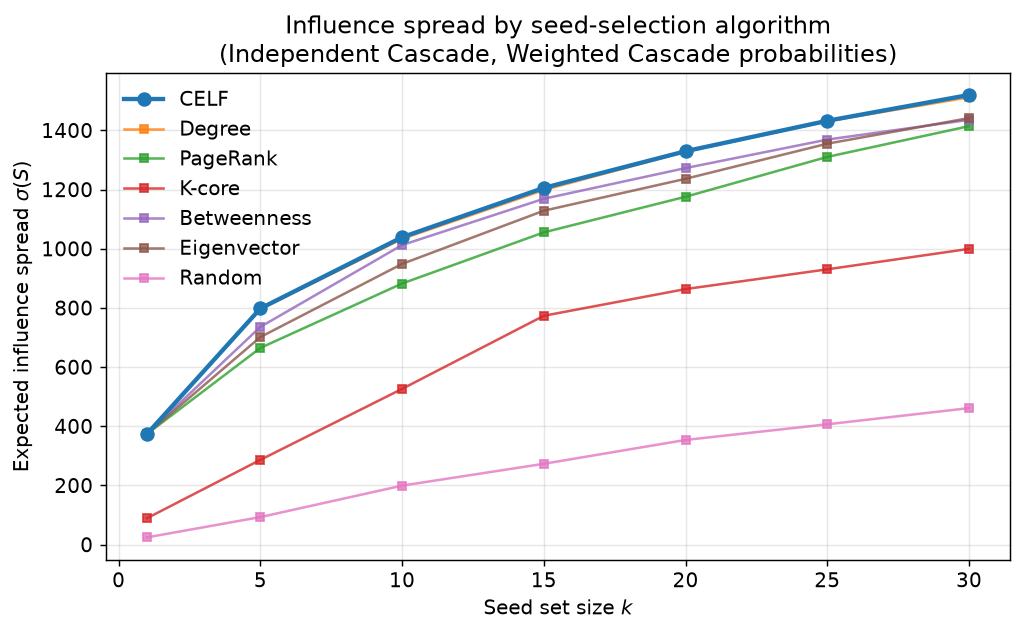

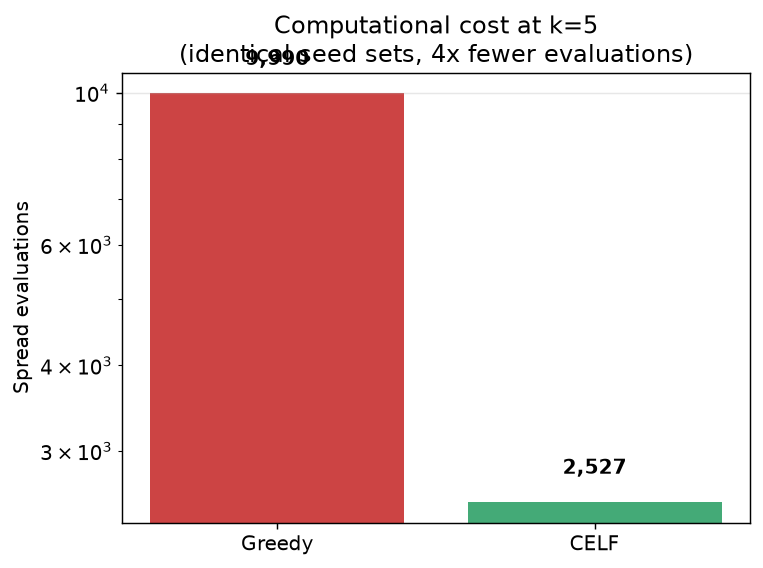

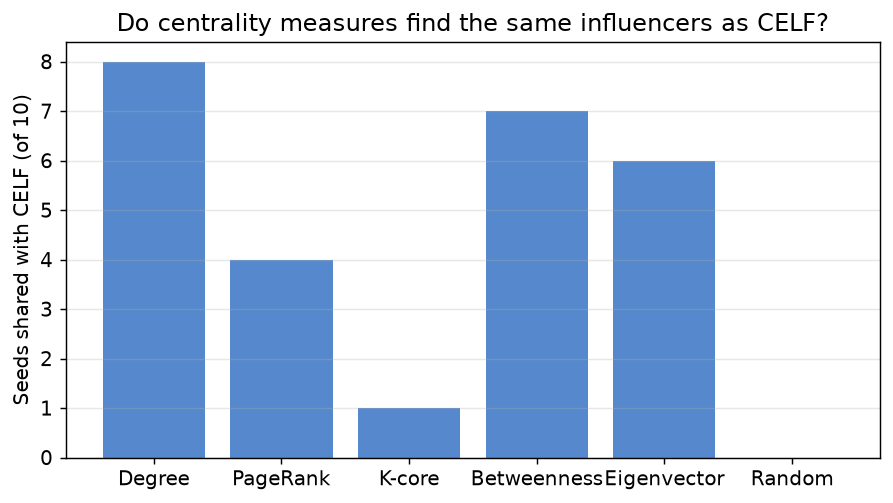


Overlap with CELF: {'Degree': 8, 'PageRank': 4, 'K-core': 1, 'Betweenness': 7, 'Eigenvector': 6, 'Random': 0}

>>> If overlap is LOW, that is a genuine finding: centrality != influence.


In [26]:
# --- FIGURE 1: spread vs k ---
fig, ax = plt.subplots(figsize=(8,5))
for alg in results.algorithm.unique():
    d = results[results.algorithm==alg].sort_values("k")
    style = dict(marker="o", lw=2.4, ms=7, zorder=5) if alg=="CELF" else dict(marker="s", lw=1.4, ms=4, alpha=.8)
    ax.plot(d.k, d.spread, label=alg, **style)
ax.set_xlabel("Seed set size $k$"); ax.set_ylabel(r"Expected influence spread $\sigma(S)$")
ax.set_title("Influence spread by seed-selection algorithm\n(Independent Cascade, Weighted Cascade probabilities)")
ax.legend(frameon=False); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("fig1_spread_vs_k.png", bbox_inches="tight"); plt.show()

# --- FIGURE 2: CELF vs Greedy efficiency ---
fig, ax = plt.subplots(figsize=(6,4.5))
bars = ax.bar(["Greedy","CELF"], [ev_greedy, ev_celf_cmp], color=["#c44","#4a7"])
ax.set_ylabel("Spread evaluations"); ax.set_yscale("log")
ax.set_title(f"Computational cost at k={k_cmp}\n(identical seed sets, {ev_greedy/max(ev_celf_cmp,1):.0f}x fewer evaluations)")
for b,v in zip(bars,[ev_greedy,ev_celf_cmp]):
    ax.text(b.get_x()+b.get_width()/2, v*1.1, f"{v:,}", ha="center", fontweight="bold")
ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("fig2_celf_vs_greedy.png", bbox_inches="tight"); plt.show()

# --- FIGURE 3: seed overlap (Experiment D) ---
celf_set = set(S_celf[:min(10,K_MAX)])
ov = {name: len(celf_set & set(s[:min(10,K_MAX)])) for name, s in baselines.items()}
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(list(ov.keys()), list(ov.values()), color="#5588cc")
ax.set_ylabel(f"Seeds shared with CELF (of {len(celf_set)})")
ax.set_title("Do centrality measures find the same influencers as CELF?")
ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig("fig3_seed_overlap.png", bbox_inches="tight"); plt.show()
print("\nOverlap with CELF:", ov)
print("\n>>> If overlap is LOW, that is a genuine finding: centrality != influence.")

---
## Cell 11 — Experiment E: sensitivity check

Re-run CELF under the **weight-derived** probability model. If the seed set is largely stable,
your result is robust to the probability assumption — a strong claim for the Discussion section.
If it shifts substantially, report that honestly as a limitation. Either outcome is publishable;
hiding the check is not.

In [27]:
k_sens = min(10, K_MAX)
WORLDS_W = sample_worlds(ADJ_W, MC_MAIN, CRN_SEED)
S_alt, sp_alt, _, _, _ = celf(WORLDS_W, k_sens, pool, verbose=False)
overlap = len(set(S_celf[:k_sens]) & set(S_alt))
print(f"Weighted Cascade seeds : {S_celf[:k_sens]}")
print(f"Weight-derived seeds   : {S_alt}")
print(f"\noverlap: {overlap}/{k_sens} ({100*overlap/k_sens:.0f}%)")
print("STABLE - robust to probability model" if overlap >= 0.6*k_sens
      else "SHIFTED - report as a limitation")

CELF first pass: 100%|██████████| 2000/2000 [10:27<00:00,  3.19it/s]


Weighted Cascade seeds : ['u_7645c5aa9d5f', 'u_9c2bfcf65852', 'u_e983e1de91c6', 'u_da4611ffd982', 'u_0cb2e49a48bf', 'u_26277852db5b', 'u_8f9687ab44a4', 'u_68f80fcfd8cc', 'u_e188ab5477b9', 'u_e883ed61b279']
Weight-derived seeds   : ['u_88ffdaebcc65', 'u_878e2ecc238e', 'u_74e8e6f7a0e3', 'u_756b8d5fc089', 'u_a17e504447dd', 'u_0256999e1095', 'u_f79c405081a1', 'u_6e5687389f88', 'u_68d08e777ede', 'u_09738d5c4e22']

overlap: 0/10 (0%)
SHIFTED - report as a limitation


---
## Cell 12 — Export seeds for the Gephi figure

Writes `celf_seeds.csv`. Import it into Gephi via
**Data Laboratory -> Import Spreadsheet -> Nodes table -> Append to existing workspace**.
Gephi merges on `Id`, then colour nodes by `is_seed` and size by `seed_rank`.

That produces the seed-highlight figure: your network coloured by community with the
CELF-selected influencers marked — the single image that shows data, method and result together.

In [28]:
seed_rows = []
for i, nid in enumerate(S_celf, start=1):
    seed_rows.append({"Id": nid, "is_seed": "SEED", "seed_rank": len(S_celf) - i + 1})
for nid in G.nodes():
    if nid not in set(S_celf):
        seed_rows.append({"Id": nid, "is_seed": "not_seed", "seed_rank": 0})

pd.DataFrame(seed_rows).to_csv("celf_seeds.csv", index=False)
print(f"wrote celf_seeds.csv ({len(seed_rows):,} rows, {len(S_celf)} marked SEED)")

summary = {
  "nodes": n, "edges": m, "mc_main": MC_MAIN, "candidate_pool": CANDIDATE_POOL,
  "seed": SEED, "k_max": K_MAX,
  "celf_seeds": S_celf, "celf_final_spread": sp_celf,
  "celf_evaluations": ev_celf, "celf_runtime_s": t_celf,
  "greedy_vs_celf": {"k": k_cmp, "identical": set(S_greedy)==set(S_celf_cmp),
                     "greedy_evals": ev_greedy, "celf_evals": ev_celf_cmp},
  "seed_overlap_with_baselines": ov,
}
json.dump(summary, open("experiment_summary.json","w"), indent=2)
print("wrote experiment_summary.json  <- quote these numbers in your report")
print(f"\nHEADLINE: CELF reached sigma={sp_celf:.1f} at k={K_MAX} "
      f"({100*sp_celf/n:.1f}% of the network) using {ev_celf:,} evaluations")

wrote celf_seeds.csv (6,434 rows, 30 marked SEED)
wrote experiment_summary.json  <- quote these numbers in your report

HEADLINE: CELF reached sigma=1519.9 at k=30 (23.6% of the network) using 4,997 evaluations
